In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

from sklearn.model_selection import GridSearchCV

In [2]:
DATA_PATH = Path("../data/raw/customer_churn.csv")

df = pd.read_csv(DATA_PATH)

# Convert TotalCharges to numeric.
# Blank strings become NaN.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype("str").str.strip(),
    errors="coerce"
)

# The 11 missing values were associated with zero-tenure customers.
# Apply the documented assumption that their total charges are zero.
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Separate features and target.
X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

assert y.notna().all(), "Unexpected target labels detected."
assert X.isna().sum().sum() == 0, "Unexpected missing features detected."

print("Dataset shape:", df.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (7043, 21)
Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (5634, 19)
Testing set: (1409, 19)

Training class distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing class distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [4]:
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_features.append("SeniorCitizen")

numerical_features = [
    column
    for column in X.select_dtypes(include=["number"]).columns
    if column not in categorical_features
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", numerical_features)

Categorical features: 16
Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']


In [5]:
# constructing a preprocessing pipeline

numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [6]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_predictions))
print("Baseline Precision:", precision_score(
    y_test, baseline_predictions, zero_division=0
))
print("Baseline Recall:", recall_score(
    y_test, baseline_predictions, zero_division=0
))
print("Baseline F1-score:", f1_score(
    y_test, baseline_predictions, zero_division=0
))

Baseline Accuracy: 0.7345635202271115
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1-score: 0.0


In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    )
}

print("Models defined:")
for model_name in models:
    print("-", model_name)

Models defined:
- Logistic Regression
- KNN
- Decision Tree
- SVM


In [8]:
pipelines = {
    model_name: Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )
    for model_name, model in models.items()
}

print("Complete pipelines created:", len(pipelines))

Complete pipelines created: 4


In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for model_name, pipeline in pipelines.items():

    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

results_df = pd.DataFrame(cv_results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

Evaluating Logistic Regression...
Evaluating KNN...
Evaluating Decision Tree...
Evaluating SVM...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 Std
0,Logistic Regression,0.8019,0.6521,0.5438,0.5924,0.8461,0.0298
1,SVM,0.8048,0.6811,0.4983,0.5753,0.7988,0.0136
2,KNN,0.7657,0.5617,0.5324,0.5466,0.7821,0.0132
3,Decision Tree,0.7302,0.4919,0.4923,0.4919,0.6547,0.0173


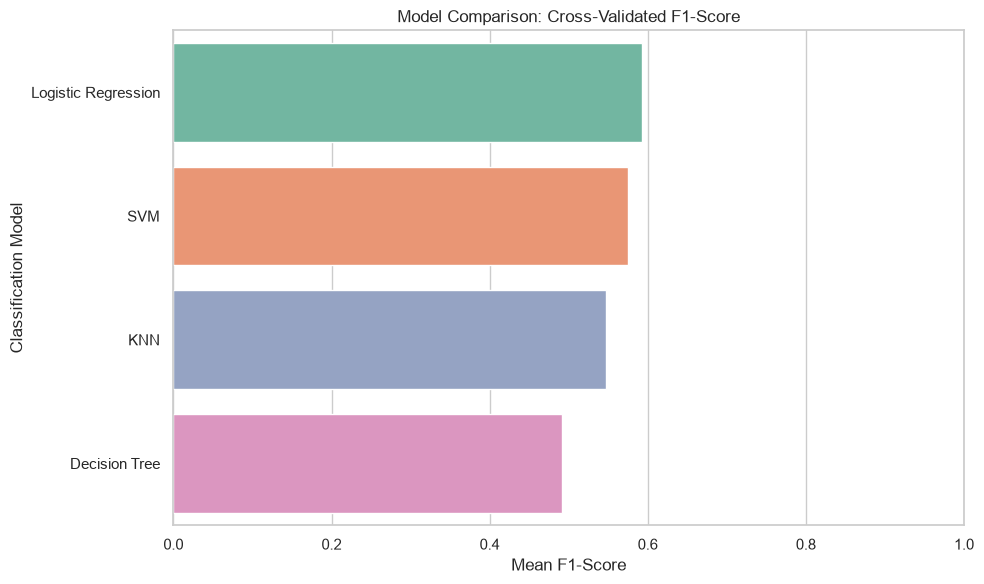

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="F1-Score",
    y="Model",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Model Comparison: Cross-Validated F1-Score")
plt.xlabel("Mean F1-Score")
plt.ylabel("Classification Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

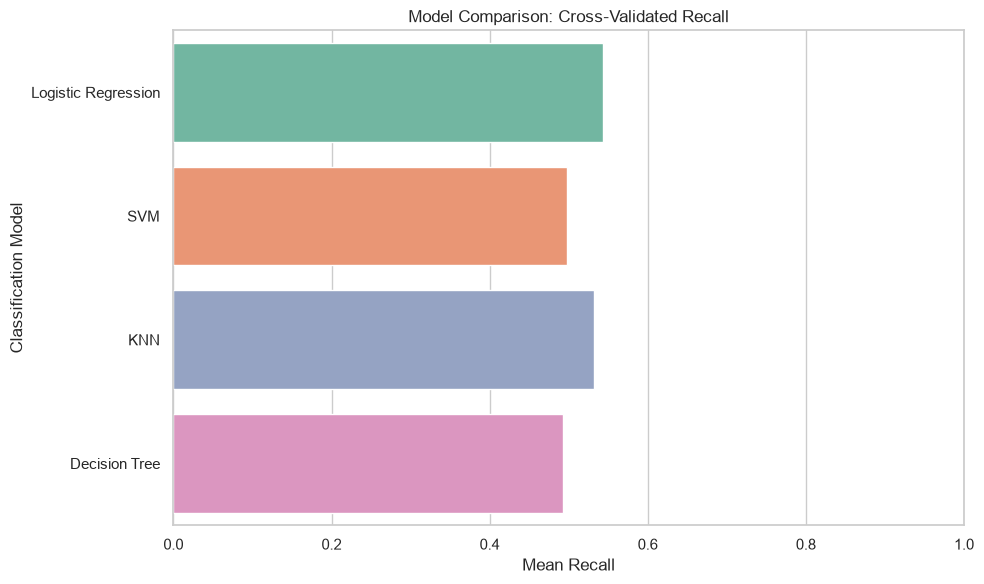

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Recall",
    y="Model",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Model Comparison: Cross-Validated Recall")
plt.xlabel("Mean Recall")
plt.ylabel("Classification Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [12]:
# Display model comparison results
display(
    results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 Std
0,Logistic Regression,0.8019,0.6521,0.5438,0.5924,0.8461,0.0298
1,SVM,0.8048,0.6811,0.4983,0.5753,0.7988,0.0136
2,KNN,0.7657,0.5617,0.5324,0.5466,0.7821,0.0132
3,Decision Tree,0.7302,0.4919,0.4923,0.4919,0.6547,0.0173


In [13]:
# Identify the model with the highest mean F1-score
best_f1_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best model based on mean F1-score:")
print(best_f1_model)

Best model based on mean F1-score:
Model        Logistic Regression
Accuracy                0.801918
Precision               0.652094
Recall                  0.543813
F1-Score                0.592412
ROC-AUC                 0.846149
F1 Std                  0.029782
Name: 0, dtype: object


In [14]:
logistic_pipeline = pipelines["Logistic Regression"]

logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

logistic_search.fit(X_train, y_train)

print("Best parameters:")
print(logistic_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(logistic_search.best_score_, 4))

Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best cross-validation F1-score:
0.6288


In [16]:
svm_pipeline = pipelines["SVM"]

svm_param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__class_weight": [None, "balanced"]
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

svm_search.fit(X_train, y_train)

print("Best parameters:")
print(svm_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(svm_search.best_score_, 4))

c:\Users\alwin\.conda\envs\customer-churn\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__kernel': 'rbf'}

Best cross-validation F1-score:
0.6236


In [17]:
tuned_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "CV F1-score": logistic_search.best_score_,
        "Best Parameters": logistic_search.best_params_
    },
    {
        "Model": "SVM",
        "CV F1-score": svm_search.best_score_,
        "Best Parameters": svm_search.best_params_
    }
])

display(tuned_results.round(4))

,Model,CV F1-score,Best Parameters
0,Logistic Regression,0.6288,"{'classifier__C': 0.1, 'classifier__class_weig..."
1,SVM,0.6236,"{'classifier__C': 1, 'classifier__class_weight..."


In [18]:
# Update this after reviewing tuned_results.
best_search = logistic_search  # Replace if SVM is selected

final_model = best_search.best_estimator_

print("Selected model:")
print(best_search.best_estimator_.named_steps["classifier"])

print("\nBest parameters:")
print(best_search.best_params_)

Selected model:
LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000,
                   random_state=42)

Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred = final_model.predict(X_test)

print("Test-set Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test-set Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Test-set Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("Test-set F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

Test-set Accuracy: 0.7417
Test-set Precision: 0.5087
Test-set Recall: 0.7861
Test-set F1-score: 0.6176


In [20]:
if hasattr(final_model, "predict_proba"):
    y_scores = final_model.predict_proba(X_test)[:, 1]
else:
    y_scores = final_model.decision_function(X_test)

print("Test-set ROC-AUC:", round(
    roc_auc_score(y_test, y_scores), 4
))

Test-set ROC-AUC: 0.8408


In [21]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

      Stayed     0.9037    0.7256    0.8049      1035
     Churned     0.5087    0.7861    0.6176       374

    accuracy                         0.7417      1409
   macro avg     0.7062    0.7559    0.7113      1409
weighted avg     0.7989    0.7417    0.7552      1409



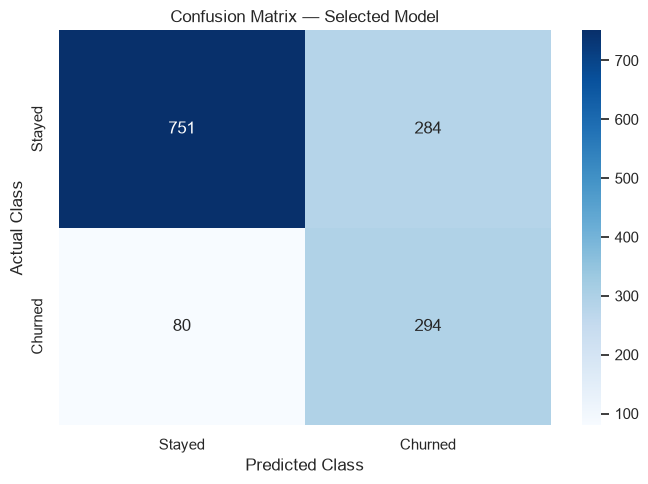

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Confusion Matrix — Selected Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [23]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "customer_churn_pipeline.joblib"

joblib.dump(final_model, MODEL_PATH)

print("Model saved to:", MODEL_PATH)

Model saved to: ..\models\customer_churn_pipeline.joblib
